Tratamento e Diagnóstico

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")
display(df.head())
print(df.shape)
df.info()
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.0,1200,180,310,4100,145,4300
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.0,720,140,260,2300,92,2500
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.0,980,195,410,1900,105,2300
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.0,650,120,300,2500,120,3800
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.0,2600,350,620,5300,190,5200


(24, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   data_publicacao       24 non-null     object 
 1   portal                24 non-null     object 
 2   titulo                24 non-null     object 
 3   modalidade            24 non-null     object 
 4   tipo_conteudo         24 non-null     object 
 5   turno_publicacao      24 non-null     object 
 6   visualizacoes         24 non-null     int64  
 7   usuarios_unicos       24 non-null     int64  
 8   tempo_medio_segundos  23 non-null     float64
 9   curtidas              24 non-null     int64  
 10  comentarios           24 non-null     int64  
 11  compartilhamentos     24 non-null     int64  
 12  cliques_relacionados  24 non-null     int64  
 13  novos_assinantes      24 non-null     int64  
 14  receita_publicitaria  24 non-null     int64  
dtypes: float64(1), i

In [ ]:
dados = df.copy()
dados["modalidade"] = dados["modalidade"].str.strip()
dados["data_publicacao"] = pd.to_datetime(
dados["data_publicacao"], errors="coerce"
)

Verificação

In [ ]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   data_publicacao       24 non-null     datetime64[ns]
 1   portal                24 non-null     object        
 2   titulo                24 non-null     object        
 3   modalidade            24 non-null     object        
 4   tipo_conteudo         24 non-null     object        
 5   turno_publicacao      24 non-null     object        
 6   visualizacoes         24 non-null     int64         
 7   usuarios_unicos       24 non-null     int64         
 8   tempo_medio_segundos  23 non-null     float64       
 9   curtidas              24 non-null     int64         
 10  comentarios           24 non-null     int64         
 11  compartilhamentos     24 non-null     int64         
 12  cliques_relacionados  24 non-null     int64         
 13  novos_assinantes      

Métricas

In [ ]:
dados["total_interacoes"] = (
dados["curtidas"] + dados["comentarios"]
+ dados["compartilhamentos"]
)
dados["taxa_engajamento_pct"] = (
dados["total_interacoes"] / dados["visualizacoes"]
) * 100
dados["taxa_recirculacao_pct"] = (
dados["cliques_relacionados"] / dados["visualizacoes"]
) * 100
dados["taxa_conversao_pct"] = (
dados["novos_assinantes"] / dados["cliques_relacionados"]
) * 100
dados["rpm"] = (
dados["receita_publicitaria"] / dados["visualizacoes"]
) * 1000
dados["frequencia_media"] = (
dados["visualizacoes"] / dados["usuarios_unicos"]
)

Agrupamento

In [ ]:
import pandas as pd

# 1. Tratamento inicial e criação da coluna base de interações
dados = df.copy()
dados["modalidade"] = dados["modalidade"].str.strip()
dados["data_publicacao"] = pd.to_datetime(dados["data_publicacao"], errors="coerce")
dados["total_interacoes"] = dados["curtidas"] + dados["comentarios"] + dados["compartilhamentos"]

# 2. Definir as colunas de agrupamento e as colunas numéricas que precisamos somar
colunas_agrupamento = ["modalidade", "tipo_conteudo", "turno_publicacao"]
colunas_soma = [
    "total_interacoes", "visualizacoes", "cliques_relacionados",
    "novos_assinantes", "receita_publicitaria", "usuarios_unicos"
]

# 3. Criar o novo DataFrame agrupado somando os numeradores e denominadores
dados_agrupados = dados.groupby(colunas_agrupamento)[colunas_soma].sum().reset_index()

# 4. Recalcular as métricas percentuais/taxas com base nas somas do grupo
dados_agrupados["taxa_engajamento_pct"] = (
    dados_agrupados["total_interacoes"] / dados_agrupados["visualizacoes"]
) * 100

dados_agrupados["taxa_recirculacao_pct"] = (
    dados_agrupados["cliques_relacionados"] / dados_agrupados["visualizacoes"]
) * 100

dados_agrupados["taxa_conversao_pct"] = (
    dados_agrupados["novos_assinantes"] / dados_agrupados["cliques_relacionados"]
) * 100

dados_agrupados["rpm"] = (
    dados_agrupados["receita_publicitaria"] / dados_agrupados["visualizacoes"]
) * 1000

dados_agrupados["frequencia_media"] = (
    dados_agrupados["visualizacoes"] / dados_agrupados["usuarios_unicos"]
)

# 5. Visualizar o resultado final COMPLETO (sem o .head)
display(dados_agrupados)

,modalidade,tipo_conteudo,turno_publicacao,total_interacoes,visualizacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,usuarios_unicos,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,Automobilismo,Análise,Tarde,1155,26000,2800,138,4200,21000,4.442308,10.769231,4.928571,161.538462,1.238095
1,Automobilismo,Entrevista,Noite,1315,23000,2600,130,3900,18500,5.717391,11.304348,5.000000,169.565217,1.243243
2,Automobilismo,Notícia,Manhã,780,20000,2100,105,3400,16500,3.900000,10.500000,5.000000,170.000000,1.212121
3,Automobilismo,Reportagem,Manhã,1340,27000,3100,155,4700,22000,4.962963,11.481481,5.000000,174.074074,1.227273
4,Automobilismo,Reportagem,Tarde,1070,24000,2500,120,3800,19500,4.458333,10.416667,4.800000,158.333333,1.230769
5,Automobilismo,Vídeo,Noite,1460,29000,3000,145,4400,23500,5.034483,10.344828,4.833333,151.724138,1.234043
6,Basquete,Análise,Manhã,915,22000,2000,88,2600,18500,4.159091,9.090909,4.400000,118.181818,1.189189
7,Basquete,Análise,Tarde,1120,28000,2300,92,2500,22500,4.000000,8.214286,4.000000,89.285714,1.244444
8,Basquete,Entrevista,Noite,1620,26000,2400,115,3100,21000,6.230769,9.230769,4.791667,119.230769,1.238095
9,Basquete,Notícia,Manhã,1155,31000,2100,70,2200,25500,3.725806,6.774194,3.333333,70.967742,1.215686


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")
print(df.columns.tolist())

['data_publicacao', 'portal', 'titulo', 'modalidade', 'tipo_conteudo', 'turno_publicacao', 'visualizacoes', 'usuarios_unicos', 'tempo_medio_segundos', 'curtidas', 'comentarios', 'compartilhamentos', 'cliques_relacionados', 'novos_assinantes', 'receita_publicitaria']


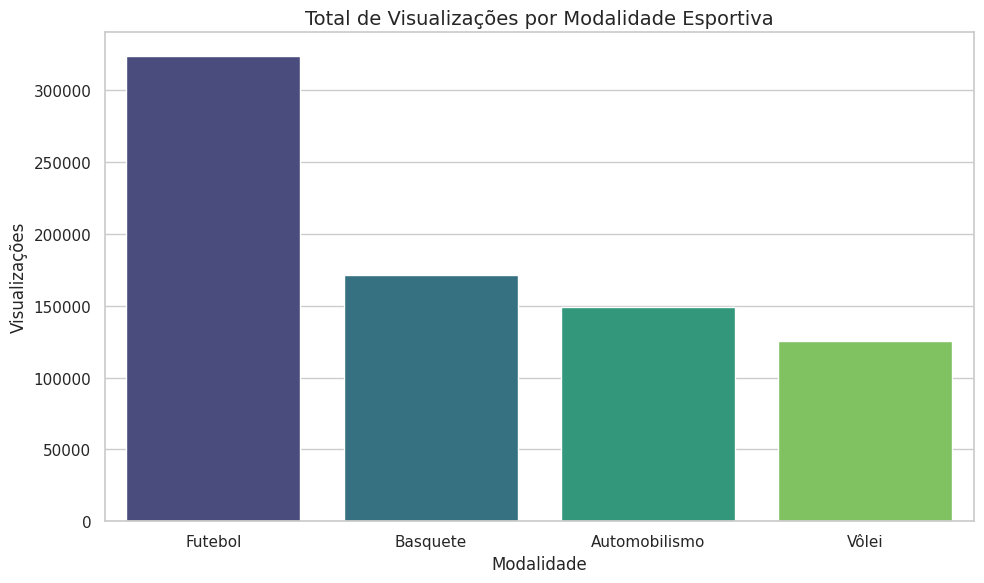

1. Visualizações por modalidade:
      modalidade  visualizacoes
2        Futebol         324000
1       Basquete         171000
0  Automobilismo         149000
3          Vôlei         125500


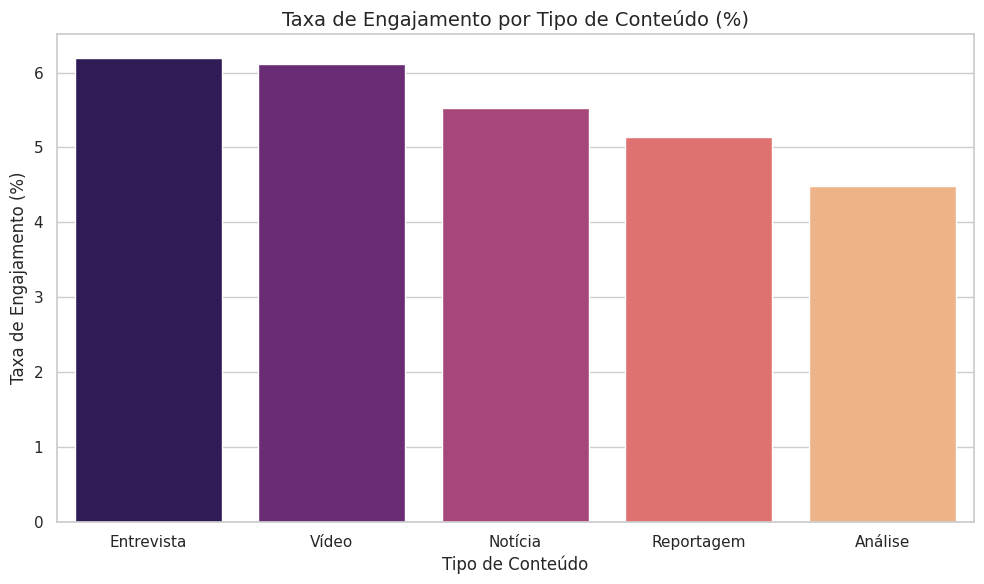


2. Taxa de engajamento por tipo de conteúdo:
  tipo_conteudo  taxa_engajamento
1    Entrevista          6.201754
4         Vídeo          6.109677
2       Notícia          5.533186
3    Reportagem          5.136201
0       Análise          4.485185


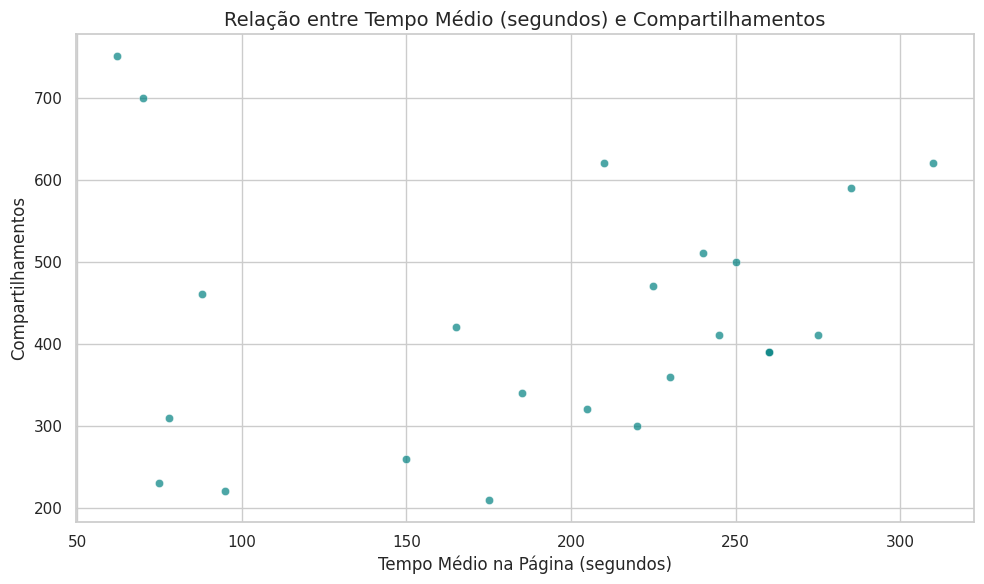


3. Correlação Tempo Médio x Compartilhamentos: 0.09778925522768074


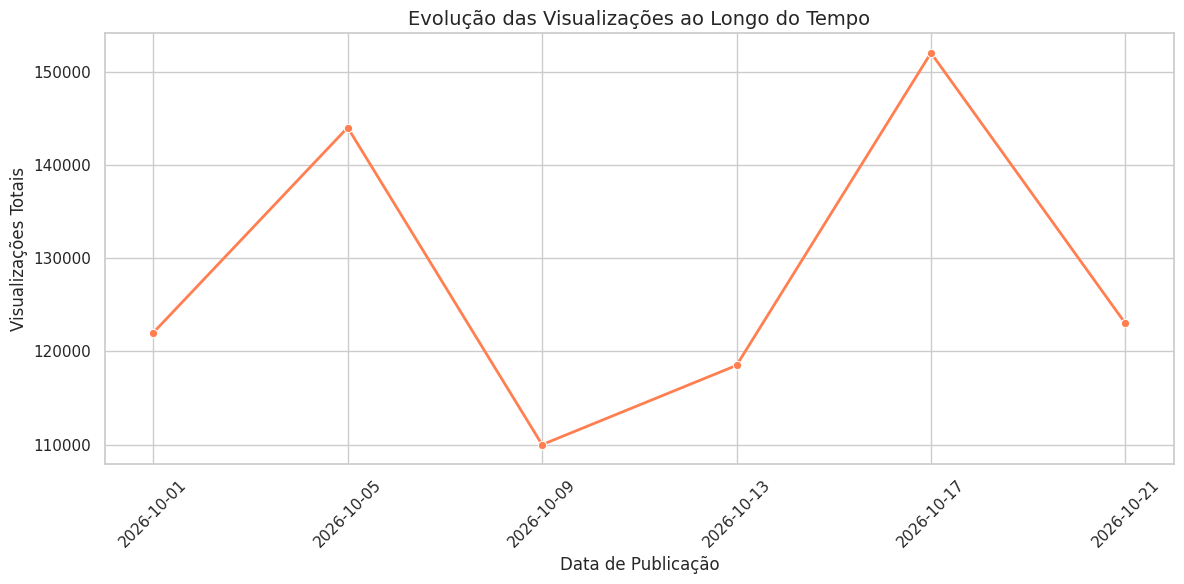

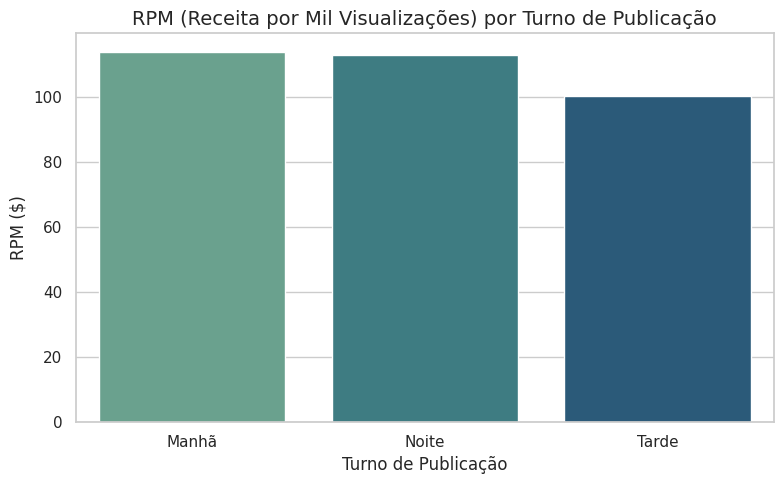


5. RPM por turno:
  turno_publicacao         rpm
0            Manhã  113.872832
1            Noite  112.987013
2            Tarde  100.173310


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de estilo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Carregamento e tratamento inicial
df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")
df["modalidade"] = df["modalidade"].str.strip()
df["data_publicacao"] = pd.to_datetime(df["data_publicacao"], errors="coerce")
df["total_interacoes"] = df["curtidas"] + df["comentarios"] + df["compartilhamentos"]

# ---------------------------------------------------------
# 1. Gráfico de barras com visualizações por modalidade
# ---------------------------------------------------------
vis_por_modalidade = df.groupby("modalidade")["visualizacoes"].sum().reset_index()
vis_por_modalidade = vis_por_modalidade.sort_values(by="visualizacoes", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=vis_por_modalidade,
    x="modalidade",
    y="visualizacoes",
    hue="modalidade",
    legend=False,
    palette="viridis"
)
plt.title("Total de Visualizações por Modalidade Esportiva", fontsize=14)
plt.xlabel("Modalidade", fontsize=12)
plt.ylabel("Visualizações", fontsize=12)
plt.tight_layout()
plt.savefig("grafico1.png")
plt.show()

print("1. Visualizações por modalidade:")
print(vis_por_modalidade)

# ---------------------------------------------------------
# 2. Gráfico de barras com taxa de engajamento por tipo de conteúdo
# ---------------------------------------------------------
eng_por_conteudo = df.groupby("tipo_conteudo")[["total_interacoes", "visualizacoes"]].sum().reset_index()
eng_por_conteudo["taxa_engajamento"] = (eng_por_conteudo["total_interacoes"] / eng_por_conteudo["visualizacoes"]) * 100
eng_por_conteudo = eng_por_conteudo.sort_values(by="taxa_engajamento", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=eng_por_conteudo,
    x="tipo_conteudo",
    y="taxa_engajamento",
    hue="tipo_conteudo",
    legend=False,
    palette="magma"
)
plt.title("Taxa de Engajamento por Tipo de Conteúdo (%)", fontsize=14)
plt.xlabel("Tipo de Conteúdo", fontsize=12)
plt.ylabel("Taxa de Engajamento (%)", fontsize=12)
plt.tight_layout()
plt.savefig("grafico2.png")
plt.show()

print("\n2. Taxa de engajamento por tipo de conteúdo:")
print(eng_por_conteudo[["tipo_conteudo", "taxa_engajamento"]])

# ---------------------------------------------------------
# 3. Gráfico de dispersão relacionando tempo médio e compartilhamentos
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="tempo_medio_segundos", y="compartilhamentos", alpha=0.7, color="teal")
plt.title("Relação entre Tempo Médio (segundos) e Compartilhamentos", fontsize=14)
plt.xlabel("Tempo Médio na Página (segundos)", fontsize=12)
plt.ylabel("Compartilhamentos", fontsize=12)
plt.tight_layout()
plt.savefig("grafico3.png")
plt.show()

corr_tempo_comp = df["tempo_medio_segundos"].corr(df["compartilhamentos"])
print(f"\n3. Correlação Tempo Médio x Compartilhamentos: {corr_tempo_comp}")

# ---------------------------------------------------------
# 4. Gráfico de linha com evolução das visualizações
# ---------------------------------------------------------
vis_por_data = df.groupby(df["data_publicacao"].dt.date)["visualizacoes"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=vis_por_data, x="data_publicacao", y="visualizacoes", marker="o", color="coral", linewidth=2)
plt.title("Evolução das Visualizações ao Longo do Tempo", fontsize=14)
plt.xlabel("Data de Publicação", fontsize=12)
plt.ylabel("Visualizações Totais", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("grafico4.png")
plt.show()

# ---------------------------------------------------------
# 5. Comparação do RPM por turno de publicação
# ---------------------------------------------------------
rpm_por_turno = df.groupby("turno_publicacao")[["receita_publicitaria", "visualizacoes"]].sum().reset_index()
rpm_por_turno["rpm"] = (rpm_por_turno["receita_publicitaria"] / rpm_por_turno["visualizacoes"]) * 1000
rpm_por_turno = rpm_por_turno.sort_values(by="rpm", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=rpm_por_turno,
    x="turno_publicacao",
    y="rpm",
    hue="turno_publicacao",
    legend=False,
    palette="crest"
)
plt.title("RPM (Receita por Mil Visualizações) por Turno de Publicação", fontsize=14)
plt.xlabel("Turno de Publicação", fontsize=12)
plt.ylabel("RPM ($)", fontsize=12)
plt.tight_layout()
plt.savefig("grafico5.png")
plt.show()

print("\n5. RPM por turno:")
print(rpm_por_turno[["turno_publicacao", "rpm"]])

Questão 1 -
• a) Quantos registros e variáveis existem?

• b) Quais colunas são categóricas, numéricas e temporais?

Categóricas - modalidade 	tipo_conteudo

Temporais - turno_publicacao

Numéricas -  	total_interacoes 	visualizacoes 	cliques_relacionados 	novos_assinantes 	receita_publicitaria 	usuarios_unicos 	taxa_engajamento_pct 	taxa_recirculacao_pct 	taxa_conversao_pct 	rpm 	frequencia_media

• c) Que problema de qualidade foi encontrado?

Havia uma categoria inconsistente na coluna de modalidade (espaço em branco antes/depois do nome, como " Futebol "), que foi corrigida com o comando .str.strip().

Existência de valores ausentes.

• d) Por que um valor ausente não deve ser automaticamente substituído por zero?

Geraria uma imprecisão na análise dos dados e na tomada de decisão, uma vez que não necessariamente um valor ausente representa zero, às vezes aquele valor foi apenas atríbuido de maneira errônea à um tipo de dado diferente.

Questão 2 Métricas
• Selecione o primeiro conteúdo e calcule taxa de engajamento, taxa de recirculação, taxa de conversão, RPM e
frequência média.
• Apresente a fórmula, o cálculo e a interpretação de cada resultado.

In [ ]:
import pandas as pd

# 1. Carregamento da base de dados
df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")

# 2. Tratamentos realizados na Etapa 2
dados = df.copy()
dados["modalidade"] = dados["modalidade"].str.strip()
dados["data_publicacao"] = pd.to_datetime(dados["data_publicacao"], errors="coerce")

# 3. Selecionando apenas o primeiro conteúdo (índice 0)
primeiro_conteudo = dados.head(1)

# 4. Exibindo a linha completa (usamos .T para transpor e facilitar a leitura na vertical)
display(primeiro_conteudo.T)

,0
data_publicacao,2026-10-01 00:00:00
portal,Site
titulo,Clássico nacional movimenta a rodada
modalidade,Futebol
tipo_conteudo,Notícia
turno_publicacao,Manhã
visualizacoes,52000
usuarios_unicos,43000
tempo_medio_segundos,78.0
curtidas,1200


### 1. Taxa de Engajamento
* **Fórmula:** `(curtidas + comentários + compartilhamentos) / visualizações * 100`
* **Cálculo:** (1.200 + 180 + 310) / 52.000 * 100
  * = 1.690 / 52.000 * 100
  * = **3,25%**
* **Interpretação:** De todas as visualizações que o conteúdo teve, 3,25% resultaram em uma interação ativa (o leitor curtiu, comentou ou compartilhou). Isso mede o nível de reação e interesse direto que a pauta despertou no público.

### 2. Taxa de Recirculação
* **Fórmula:** `cliques_relacionados / visualizações * 100`
* **Cálculo:** (4.100 / 52.000) * 100
  * = **7,88%**
*  Quase 8% das pessoas que abriram a reportagem clicaram em outros links sugeridos na página. Essa métrica avalia o poder da matéria de reter a audiência dentro do portal, evitando que o leitor saia logo após a leitura.

### 3. Taxa de Conversão
* **Fórmula:** `novos_assinantes / cliques_relacionados * 100`
* **Cálculo:** (145 / 4.100) * 100
  * = **3,53%**
*  Dos usuários que clicaram em algum link relacionado a partir dessa notícia, 3,53% decidiram assinar o portal. É um indicativo claro do valor financeiro do conteúdo e de seu apelo comercial para captar pagantes.

### 4. RPM (Receita por Mil Visualizações)
* **Fórmula:** `(receita_publicitaria / visualizações) * 1000`
* **Cálculo:** (4.300 / 52.000) * 1.000
  * = **$ 82,69**
*  A cada lote de 1.000 visualizações, a reportagem gerou aproximadamente 82 dólares em receita de anúncios. Isso ajuda a equipe de negócios a entender a rentabilidade do formato de anúncio nessa página específica.

### 5. Frequência Média
* **Fórmula:** `visualizações / usuários_unicos`
* **Cálculo:** 52.000 / 43.000
  * = **1,20**
*  Em média, cada leitor acessou a mesma notícia 1,2 vezes. Um número próximo a 1 indica que a esmagadora maioria leu a matéria uma única vez, o que é o comportamento padrão esperado para o consumo de notícias factuais.

Questão 3 Desempenho Editorial

1. Qual modalidade apresentou mais visualizações?

Futebol, acumulando um total de 324.000 visualizações (liderando isoladamente em comparação com as demais modalidades).

2. Qual tipo de conteúdo apresentou maior engajamento?

O formato de Entrevista, que atingiu uma taxa de engajamento de 6,20% (calculada pela soma de todas as interações das entrevistas dividida pela soma de todas as suas visualizações).

3. Qual conteúdo gerou mais novos assinantes?

A matéria com o título "Os melhores lances do fim de semana", responsável por gerar 190 novos assinantes em uma única publicação.

4. Qual formato apresentou maior tempo médio?

O formato de Entrevista, com uma média de 273,3 segundos (cerca de 4 minutos e 33 segundos) de retenção dos leitores na página.

5. Qual conteúdo apresentou maior RPM?

A reportagem "Tecnologia nos boxes reduz tempo de parada", que gerou o maior Retorno por Mil Visualizações (RPM), alcançando $ 174,07 a cada mil acessos.

Questão 4 Comparação entre alcance e qualidade
• Identifique um conteúdo com alto alcance e baixo engajamento; um conteúdo com menor alcance e maior
engajamento; e uma hipótese para explicar a diferença.

In [ ]:
import pandas as pd

# 1. Carregamento e tratamento básico
df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")
df["total_interacoes"] = df["curtidas"] + df["comentarios"] + df["compartilhamentos"]

# 2. Cálculo da taxa de engajamento individual (por linha)
df["taxa_engajamento_pct"] = (df["total_interacoes"] / df["visualizacoes"]) * 100

# 3. Ordenando para ver os maiores alcances (visualizações)
print("--- Maior Alcance ---")
display(df.sort_values(by="visualizacoes", ascending=False)[["titulo", "visualizacoes", "taxa_engajamento_pct"]].head(5))

# 4. Ordenando para ver os maiores engajamentos
print("\n--- Maior Engajamento ---")
display(df.sort_values(by="taxa_engajamento_pct", ascending=False)[["titulo", "visualizacoes", "taxa_engajamento_pct"]].head(5))

--- Maior Alcance ---


,titulo,visualizacoes,taxa_engajamento_pct
16,Gol nos acréscimos domina as redes,75000,5.680000
4,Os melhores lances do fim de semana,68000,5.250000
0,Clássico nacional movimenta a rodada,52000,3.250000
20,Técnico explica mudanças para a decisão,47000,5.425532
8,Pressão alta explica vitória no clássico,43000,3.744186



--- Maior Engajamento ---


,titulo,visualizacoes,taxa_engajamento_pct
22,Vitória no tie-break gera repercussão,27000,10.481481
18,Rali mais longo da partida em detalhes,24000,10.000000
14,Torcida transforma ginásio em caldeirão,19500,9.000000
2,Capitã fala sobre preparação para a final,18000,8.805556
10,Seleção anuncia convocadas para amistosos,21000,8.523810


Conteúdos de apelo de massa (como o anúncio de um clássico nacional de futebol) atraem muitos cliques casuais da página inicial, de leitores que buscam apenas consumir a informação rápida (horário do jogo, times) e sair sem interagir.

Por outro lado, conteúdos de nicho, histórias emocionantes de superação ou esportes específicos (como uma vitória suada no tie-break no vôlei) atraem um público menor, mas altamente apaixonado, segmentado e fidelizado, que tem uma propensão muito maior a curtir, compartilhar o feito e debater nos comentários.

Basicamente, tipos de consumidores de conteúdos diferentes - podemos também relacionar isso com funil de conteúdo (topo x fundo).

Questão 5 Associação entre variáveis
• Calcule a correlação entre tempo médio e compartilhamentos e entre visualizações e novos assinantes.
• Explique por que uma correlação positiva não comprova causalidade.

In [ ]:
import pandas as pd

# Carregar os dados originais
df = pd.read_csv("dataset_jornalismo_esportivo_segunda_chamada.csv")

# Calcular as correlações (método de Pearson padrão)
corr_tempo_comp = df["tempo_medio_segundos"].corr(df["compartilhamentos"])
corr_vis_assin = df["visualizacoes"].corr(df["novos_assinantes"])

print(f"Correlação Tempo Médio x Compartilhamentos: {corr_tempo_comp:.4f}")
print(f"Correlação Visualizações x Novos Assinantes: {corr_vis_assin:.4f}")

Correlação Tempo Médio x Compartilhamentos: 0.0978
Correlação Visualizações x Novos Assinantes: 0.5472


### Correlações Encontradas
* **Tempo Médio x Compartilhamentos:** 0,0978 (Correlação praticamente nula/muito fraca).
* **Visualizações x Novos Assinantes:** 0,5472 (Correlação positiva moderada).

### Por que uma correlação positiva não comprova causalidade?
Na estatística e na análise de dados, o fato de duas variáveis crescerem juntas (correlação positiva) não significa obrigatoriamente que uma é a causa direta da outra. Esse fenômeno pode ocorrer por três motivos principais:

1. **A presença de uma terceira variável (Variável de Confusão):** No caso de "Visualizações x Novos Assinantes", a causa real de ambas as métricas subirem pode ser, por exemplo, a *exclusividade da pauta*. Uma matéria exclusiva e de alta qualidade jornalística atrai muitas visualizações orgânicas e, pela mesma qualidade, convence o leitor a assinar o portal. A visualização não "causou" a assinatura; a qualidade da pauta causou ambas.
2. **Coincidência estatística:** Variáveis podem apresentar padrões semelhantes ao acaso, sem nenhuma relação lógica entre si.
3. **Causalidade reversa:** Às vezes, o efeito é, na verdade, a causa (ex: um conteúdo pode ter muitas visualizações justamente *porque* novos assinantes estão compartilhando-o em fóruns restritos).

Portanto, a correlação é apenas um indício de associação que serve para guiar investigações editoriais mais profundas, mas nunca uma prova isolada de causa e efeito.

Questão 6 Insights editoriais
• Apresente três insights na estrutura: evidência numérica → interpretação jornalística → relevância editorial

### Insight 1: O valor do engajamento em nichos
* **Evidência Numérica:** O formato de Entrevista apresentou a maior taxa média de engajamento (6,20%) e o maior tempo médio (273,3 segundos). Além disso, notícias de esportes fora do futebol (como a vitória no tie-break no vôlei, com 27 mil views) atingiram picos de engajamento acima de 10%.
* **Interpretação Jornalística:** Conteúdos aprofundados focados em personagens ou em esportes segmentados retêm a atenção e motivam a interação muito mais do que o consumo rápido de resultados factuais do futebol de massa.
* **Relevância Editorial:** A redação não deve pautar seu sucesso apenas no volume de cliques. É estratégico investir na produção de entrevistas e na cobertura de outras modalidades para fidelizar comunidades apaixonadas e criar uma base de leitores leais.

### Insight 2: A independência entre retenção e compartilhamento
* **Evidência Numérica:** A correlação estatística calculada entre o tempo médio na página e a quantidade de compartilhamentos é praticamente nula (0,0978).
* **Interpretação Jornalística:** Um leitor passar muito tempo lendo uma reportagem longa não garante que ele irá enviá-la para outras pessoas. O ato de compartilhar está ligado ao impacto rápido da manchete, à identificação emocional ou à utilidade prática do assunto, não à extensão do texto.
* **Relevância Editorial:** Se o objetivo tático de uma pauta for viralização nas redes sociais e ganho de alcance, os editores devem focar em formatos dinâmicos e manchetes de alto impacto, e não em demandar grandes textos investigativos dos repórteres para esse fim específico.

### Insight 3: Curadoria visual como motor de assinaturas
* **Evidência Numérica:** O conteúdo que mais gerou novos assinantes no portal foi o vídeo "Os melhores lances do fim de semana" (190 novas assinaturas), mesmo com alcances inferiores a notícias factuais de futebol.
* **Interpretação Jornalística:** Resumos curados que agregam valor e poupam o tempo do fã de esporte são percebidos pelo público como um produto "premium".
* **Relevância Editorial:** A estratégia de paywall (fechamento de conteúdo para assinantes) deve privilegiar conteúdos de curadoria especializada, análises táticas exclusivas e vídeos, pois é nesses formatos que o leitor enxerga um benefício claro pelo qual vale a pena pagar.

Questão 7 Recomendações
• Elabore duas recomendações contendo ação proposta, evidência, resultado esperado, métrica de
acompanhamento e forma de validação

### Recomendação 1: Diversificação da pauta focada em fidelização
* **Ação proposta:** Aumentar a frequência semanal de publicações do tipo "Entrevista" e de reportagens sobre modalidades de nicho (como vôlei e basquete).
* **Evidência:** Os dados mostraram que o formato "Entrevista" possui o maior tempo médio de leitura (273,3 segundos) e a maior taxa média de engajamento (6,20%). Além disso, pautas fora do futebol de massa atingiram picos de engajamento superiores a 8%.
* **Resultado esperado:** Aumentar a fidelização do público, criando uma audiência mais qualificada e retida dentro do portal, em vez de depender apenas de visitantes casuais rápidos.
* **Métrica de acompanhamento:** Taxa de engajamento (%) e Tempo médio na página (segundos).
* **Forma de validação:** Comparar a média mensal de engajamento do portal antes e depois da implementação da nova grade de pautas durante um trimestre.

### Recomendação 2: Estratégia de vídeos curados para captação de assinantes
* **Ação proposta:** Criar uma editoria fixa de curadoria em vídeo (como "Resumos da Rodada" ou "Melhores Lances") posicionada atrás do *paywall* (exclusiva ou com chamadas fortes para assinatura).
* **Evidência:** O vídeo "Os melhores lances do fim de semana" foi, isoladamente, o conteúdo que gerou o maior volume absoluto de novos assinantes (190), superando largamente notícias textuais com mais visualizações.
* **Resultado esperado:** Elevar o número de conversões e aumentar a receita recorrente do portal.
* **Métrica de acompanhamento:** Taxa de conversão (%) e Volume absoluto de novos assinantes.
* **Forma de validação:** Realizar um acompanhamento semanal para verificar se as assinaturas originadas a partir da nova editoria de vídeos superam a média histórica de conversão das reportagens convencionais em texto.

Questão 8 Limitações
• Informe pelo menos três dados adicionais necessários para uma análise mais completa.

### Limitações da Análise

Embora a base atual tenha fornecido boas métricas de volume e engajamento, uma análise editorial e estratégica mais completa exigiria pelo menos três dados adicionais:

1. **Origem do Tráfego (Fontes de Aquisição):** Saber se o leitor chegou à matéria via redes sociais, buscas orgânicas (Google/SEO), newsletter ou acesso direto à página inicial. Isso ajuda a entender onde distribuir melhor cada tipo de formato.
2. **Profundidade de Rolagem (Scroll Depth):** O tempo médio na página não garante leitura. Saber qual porcentagem da página o leitor efetivamente rolou mostraria se reportagens mais longas estão sendo lidas até o final ou abandonadas no primeiro parágrafo.
3. **Dispositivo de Acesso (Mobile vs. Desktop):** Saber como o usuário acessa o conteúdo é fundamental, pois impacta diretamente a taxa de cliques, a disposição da receita publicitária e a preferência por vídeos em relação a textos longos.